# Avanti Joshi
# CSE AIML
# B-B2-30
# Lab 9

In [2]:
import warnings  
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score)

from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8,5)

#load the uploaded dataset
df = pd.read_csv("Wholesale customers data.csv")

In [3]:
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [4]:
df.tail()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
435,1,3,29703,12051,16027,13135,182,2204
436,1,3,39228,1431,764,4510,93,2346
437,2,3,14531,15488,30243,437,14841,1867
438,1,3,10290,1981,2232,1038,168,2125
439,1,3,2787,1698,2510,65,477,52


In [5]:
df.shape

(440, 8)

In [6]:
df.dtypes

Channel             int64
Region              int64
Fresh               int64
Milk                int64
Grocery             int64
Frozen              int64
Detergents_Paper    int64
Delicassen          int64
dtype: object

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [8]:
df.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


In [9]:
df.isnull().sum()

Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
features = [
    "Fresh",
    "Milk",	
    "Grocery",	
    "Frozen",
    "Detergents_Paper",	
    "Delicassen"
]

X = df[features].copy()

display(X.head())

print("Number of records used for clustering:", len(X))

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


Number of records used for clustering: 440


In [12]:
#Standardize the six spending features

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [13]:
#Convert scaled valued into a DataFrame for easier inspection

X_scaled_df = pd.DataFrame(X_scaled, columns=features, index=X.index)

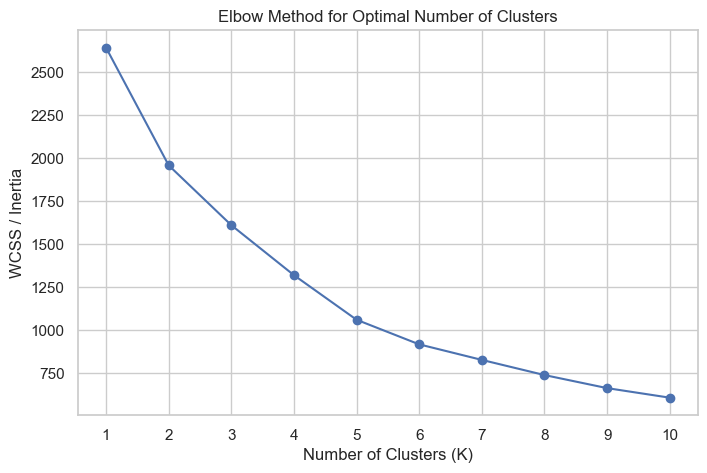

In [14]:
#Calculate WCSS (Within-Cluster Sum of Squares)

wcss = []
k_values = range(1,11)

for k in k_values:
    kmeans = KMeans(
        n_clusters = k,
        random_state = 42,
        n_init = 10
    )
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

#Plot the elbow curve
plt.figure(figsize=(8,5))
plt.plot(list(k_values),wcss,marker="o")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [15]:
#Calculate silhouette scores to support the elbow decision

silhouette_values = []

for k in range(2,11):
    model = KMeans(n_clusters = k, random_state=42, n_init = 10)
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_values.append(score)

silhouette_table = pd.DataFrame({
    "Number of Clusters" : list(range(2,11)),
    "Silhouette Score" : silhouette_values
})

display(silhouette_table.round(4))

,Number of Clusters,Silhouette Score
0,2,0.5472
1,3,0.5483
2,4,0.3485
3,5,0.3690
4,6,0.3782
5,7,0.3343
6,8,0.3201
7,9,0.3090
8,10,0.3112


In [16]:
#Suggested K based on the highest silhouette score

suggested_k = int(
    silhouette_table.loc[silhouette_table["Silhouette Score"].idxmax(), "Number of Clusters"])
print("K suggested by the highest silhouette score:", suggested_k)

K suggested by the highest silhouette score: 3


In [17]:
K = suggested_k

#Build and train the K-Means model
kmeans_model = KMeans(n_clusters = K, random_state = 42, n_init = 10)

kmeans_labels = kmeans_model.fit_predict(X_scaled)

In [18]:
#Add cluster labels to a copy of the original dataset

df_kmeans = df.copy()
df_kmeans["KMeans_Cluster"] = kmeans_labels

print("K-Means clustering completed.")
print("\nNumber of customers in each cluster:")
print(df_kmeans["KMeans_Cluster"].value_counts().sort_index())

print("\nSample records with cluster labels:")
display(df_kmeans.head())

K-Means clustering completed.

Number of customers in each cluster:
KMeans_Cluster
0     45
1    393
2      2
Name: count, dtype: int64

Sample records with cluster labels:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,KMeans_Cluster
0,2,3,12669,9656,7561,214,2674,1338,1
1,2,3,7057,9810,9568,1762,3293,1776,1
2,2,3,6353,8808,7684,2405,3516,7844,1
3,1,3,13265,1196,4221,6404,507,1788,1
4,2,3,22615,5410,7198,3915,1777,5185,1


In [19]:
# Build the hierarchical clustering model

hierarchical_model = AgglomerativeClustering(
    n_clusters = K,
    linkage = "ward",
    metric = "euclidean"
)

hierarchical_labels = hierarchical_model.fit_predict(X_scaled)

In [20]:
# store the cluster labels

df_hierarchical = df.copy()
df_hierarchical["Hierarchical_Cluster"] = hierarchical_labels

print("Hierarchical clustering completed.")
print("\nNumber of customers in each cluster:")
print(df_hierarchical["Hierarchical_Cluster"]
      .value_counts()
      .sort_index()
     )

print("\nSample records with cluster labels:")
display(df_hierarchical.head())

Hierarchical clustering completed.

Number of customers in each cluster:
Hierarchical_Cluster
0      6
1    281
2    153
Name: count, dtype: int64

Sample records with cluster labels:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Hierarchical_Cluster
0,2,3,12669,9656,7561,214,2674,1338,2
1,2,3,7057,9810,9568,1762,3293,1776,2
2,2,3,6353,8808,7684,2405,3516,7844,2
3,1,3,13265,1196,4221,6404,507,1788,1
4,2,3,22615,5410,7198,3915,1777,5185,1


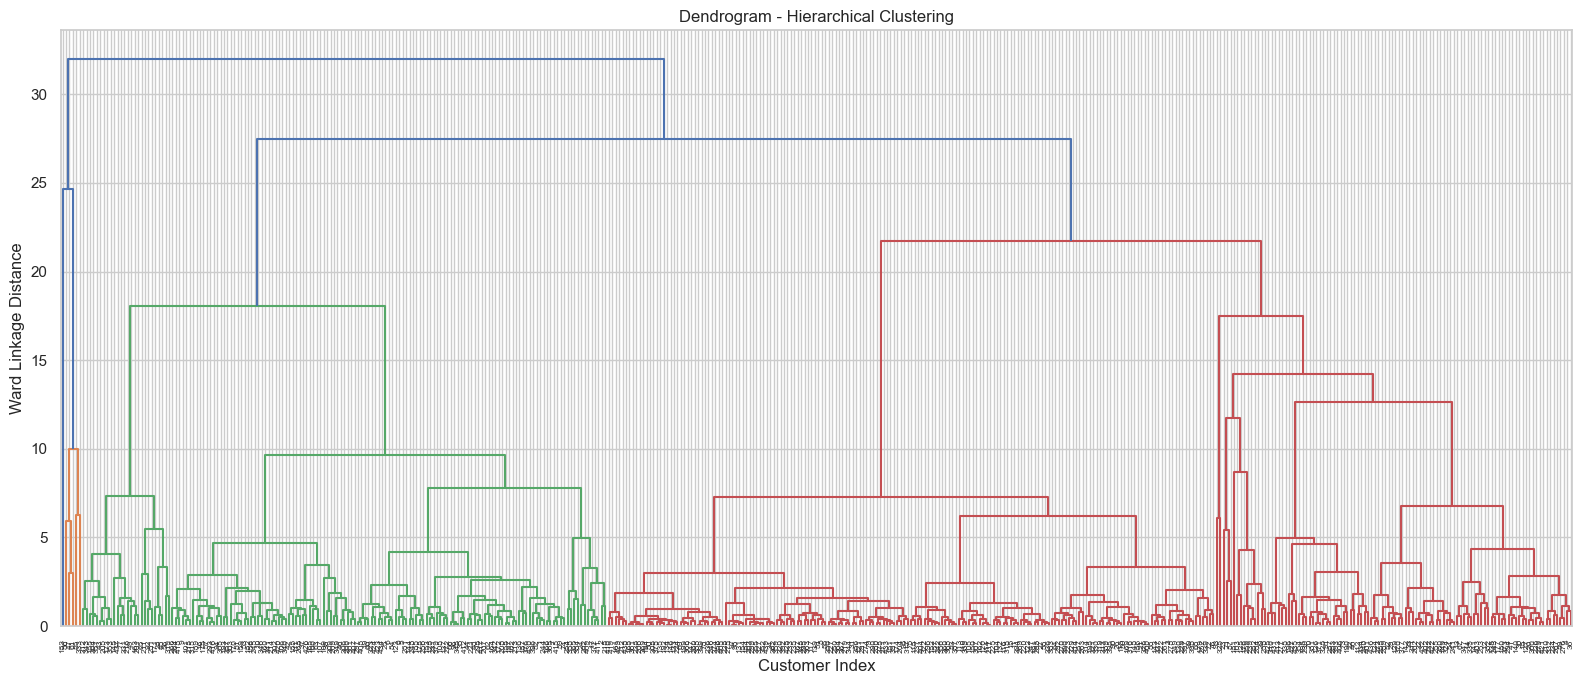

In [23]:
# Construct the linkage matrix

Z = linkage(X_scaled, method = "ward", metric = "euclidean")


# Full dendrogram

plt.figure(figsize=(16,7))
dendrogram(Z,leaf_rotation=90, leaf_font_size=6)

plt.title("Dendrogram - Hierarchical Clustering")
plt.xlabel("Customer Index")
plt.ylabel("Ward Linkage Distance")
plt.tight_layout()
plt.show()

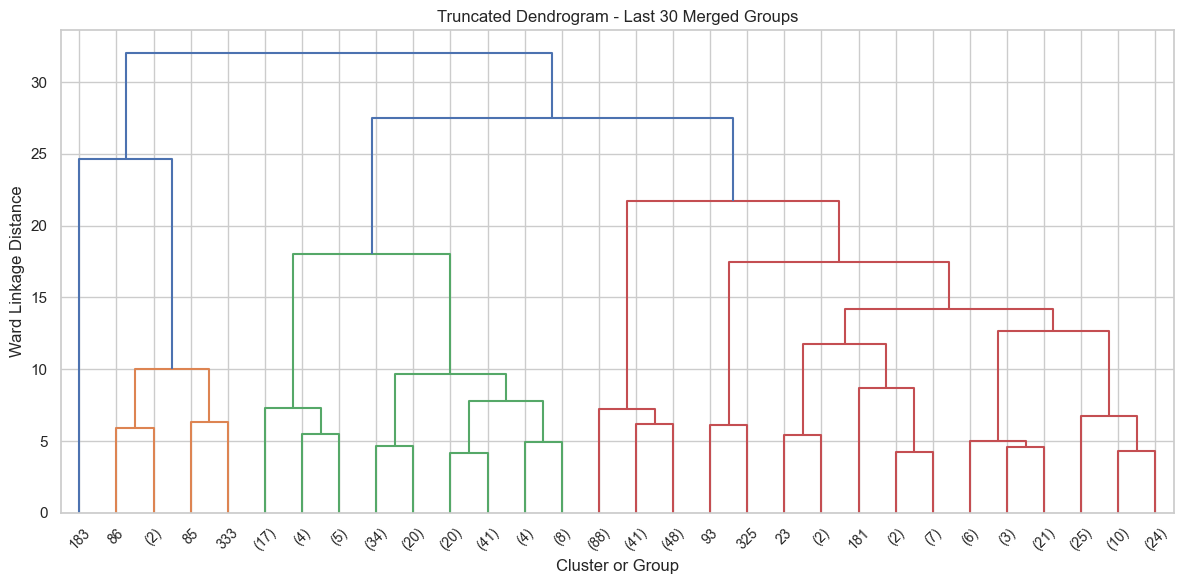

In [24]:
# Truncated dendrogram for easier interpretation

plt.figure(figsize=(12,6))
dendrogram(Z, truncate_mode = "lastp", p = 30, show_leaf_counts = True, leaf_rotation = 45)

plt.title("Truncated Dendrogram - Last 30 Merged Groups")
plt.xlabel("Cluster or Group")
plt.ylabel("Ward Linkage Distance")
plt.tight_layout()
plt.show()

In [26]:
# Reduce six scaled features to two principal components

pca = PCA(n_components = 2)
X_pca = pca.fit_transform(X_scaled)

print("Variance explained by the two PCA components:",
      round(pca.explained_variance_ratio_.sum() * 100, 2),
      "%"
     )


# Create a plotting DataFrame

plot_df = pd.DataFrame({"PC1": X_pca[:,0], 
                        "PC2": X_pca[:,1],
                        "KMeans_Cluster": kmeans_labels.astype(str),
                        "Hierarchical_Cluster": hierarchical_labels.astype(str)
                       })

Variance explained by the two PCA components: 72.46 %


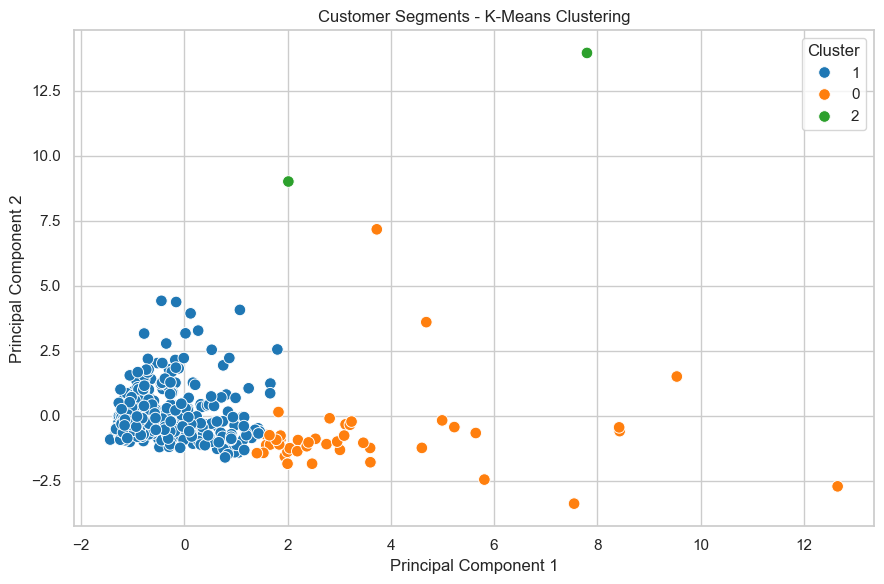

In [28]:
# KMeans visualization

plt.figure(figsize=(9,6))
sns.scatterplot(data = plot_df, x = "PC1", y = "PC2", 
               hue = "KMeans_Cluster", palette = "tab10", s = 70)

plt.title("Customer Segments - K-Means Clustering")

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")

plt.tight_layout()
plt.show()

In [29]:
# Function to calculate clustering evaluation metrics

def evaluate_clustering(X_data, labels, model_name):
    return {
        "Algorithm": model_name,
        "Number of Clusters": len(np.unique(labels)),
        "Silhouette Score": silhouette_score(X_data, labels),
        "Davies-Bouldin Score": davies_bouldin_score(X_data, labels),
        "Calinski-Harabasz Score": calinski_harabasz_score(X_data, labels)
    }

In [31]:
# Compare cluster membership sizes

cluster_sizes = pd.DataFrame({
    "K-Means": pd.Series(kmeans_labels).value_counts().sort_index(),
    "Hierarchical": pd.Series(hierarchical_labels).value_counts().sort_index()
}).fillna(0).astype(int)

print("Cluster sizes:")
display(cluster_sizes)

Cluster sizes:


,K-Means,Hierarchical
0,45,6
1,393,281
2,2,153


In [37]:
# Calculate average spending for each K-Means cluster

kmeans_profile = df[features].copy()
kmeans_profile["Cluster"] = kmeans_labels

kmeans_means = kmeans_profile.groupby("Cluster")[features].mean().round(2)

print("Average spending for each K-Means cluster:")
display(kmeans_means)

Average spending for each K-Means cluster:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,
0,10440.93,19386.42,28656.09,2190.24,13327.80,2374.20
1,12062.91,4115.10,5534.97,2940.68,1696.17,1299.11
2,34782.00,30367.00,16898.00,48701.50,755.50,26776.00


In [38]:
# Show the number and percentage of customers per cluster

cluster_distribution = pd.DataFrame({
    "Customer Count": pd.Series(kmeans_labels).value_counts().sort_index()
})

cluster_distribution["Percentage"] = (
    cluster_distribution["Customer Count"] / len(df) * 100
).round(2)

print("K-Means customer distribution:")
display(cluster_distribution)

K-Means customer distribution:


,Customer Count,Percentage
0,45,10.23
1,393,89.32
2,2,0.45


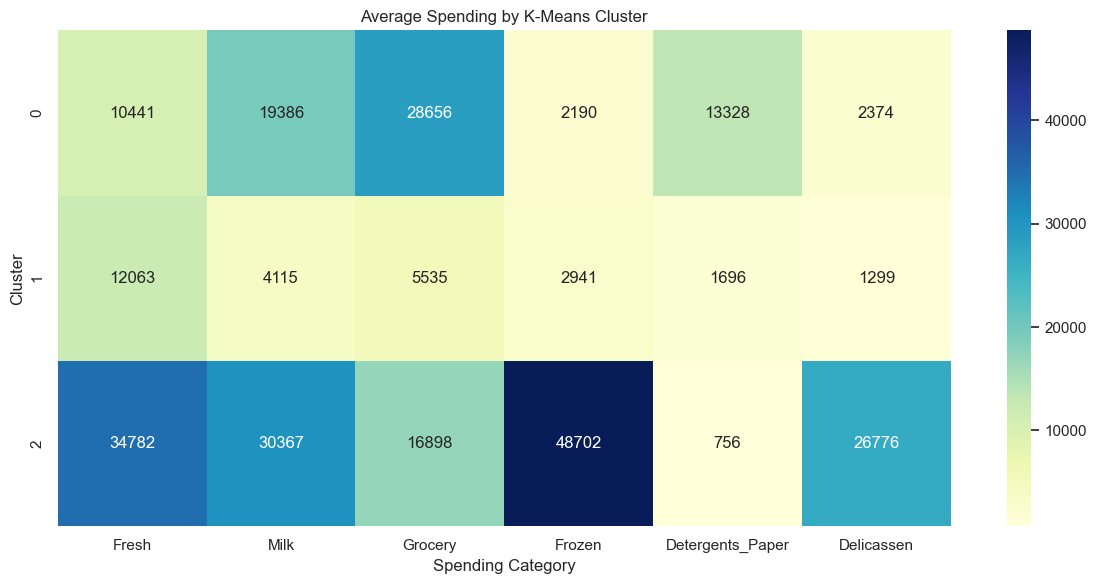

In [39]:
# Visualize average spending profiles

plt.figure(figsize=(12,6))

sns.heatmap(kmeans_means, annot=True, fmt=".0f", cmap="YlGnBu")

plt.title("Average Spending by K-Means Cluster")
plt.xlabel("Spending Category")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

In [40]:
# Compare customer channels within each K-Means cluster

channel_mix = pd.crosstab(df["Channel"], kmeans_labels, normalize = "columns") * 100

channel_mix.columns = [f"Cluster {c}" for c in channel_mix.columns]

print("Channel composition within each K-Means cluster (%):")

display(channel_mix.round(2))

Channel composition within each K-Means cluster (%):


,Cluster 0,Cluster 1,Cluster 2
Channel,,,
1,2.22,75.06,100.0
2,97.78,24.94,0.0
